# Rotated MNIST: what survives four-dimensional compression?

**Main finding:** reducing a layer's representation to four latent means changes which tasks a linear probe can read out. The effect depends on the layer: late digit and parity layers retain their main task much better than the shared layer retains digit and parity information.

## What is being compared?

Each row of the data represents **one rotated image**. We first pass the image through the frozen DNN, then analyze one layer's activations in three forms:

| Representation | What represents one image? | Role in the analysis |
|---|---|---|
| Original activations | The layer's 64 shared-neuron outputs or 32 task-neuron outputs | Context from the earlier unconstrained analysis |
| Regular VAE | 64 latent means for a shared layer, or 32 for a task layer | The VAE baseline |
| Four-dimensional VAE | Four latent means, whatever the input layer's width | The VAE with a dimensional bottleneck |

For example, the final digit layer follows either **32 activations → regular VAE → 32 latent means** or **the same 32 activations → compressed VAE → four latent means**. A linear probe is trained to predict digit, parity, or angle from each representation. The decoder reconstructs activations during VAE training; the probe reads the encoder's latent means.

**Both VAEs contain the standard KL penalty with coefficient 1.** Only latent width is deliberately varied; the resulting parameter count and number of KL summands also change. Both intermediate hidden widths are 128, so the regular VAE has no smaller intermediate bottleneck. “Regular” is an operational baseline here: latent width equals input width, while KL regularization remains present.

We reuse `MultiTaskDNN` and the single unconstrained wide 1,000-epoch checkpoint from `rotated-MNIST-VAE.ipynb`. We fit separate VAEs to all 12 post-ReLU hidden layers. The DNN remains frozen. No orthogonality comparison or zero-KL model is included.

The **Results at a glance** section below gives the compact comparison. Detailed layer, geometry, reconstruction, and uncertainty results follow. The interpretation answers the assignment's three questions: comparison with the original unconstrained analysis, differences between layers, and differences between the regular and four-dimensional VAEs.

## The two main evaluations

1. **Reconstruction error:** Can the VAE decoder recover the original layer activations from its latent code? Lower error is better. The main results show normalized sampled reconstruction SSE: 0 is perfect reconstruction, and 1 matches the error of always predicting the training-set mean activation vector. This measures neuron-activation reconstruction, not pixel reconstruction or digit accuracy.
2. **Task performance from a newly trained probe:** After freezing each VAE, train a small linear model on its latent means. Report digit/parity classification accuracy (higher is better), plus angular prediction error for rotation (lower is better). Test images and glyphs are held out. The original DNN stays frozen; these scores belong to the probe.

**CKA, RSA, Procrustes, KL, and effective rank are supporting diagnostics.** They help explain the two evaluations above and are not additional headline success criteria.

## What do Shared 0, Shared 1, and Shared 2 mean?

They are successive hidden layers in the original DNN's shared backbone. The numbering starts at zero:

| Original plot/code label | Meaning | Activations per image |
|---|---|---|
| Shared 0 / `Shared_Layer_0` | First shared hidden layer, closest to the input | 64 |
| Shared 1 / `Shared_Layer_1` | Second shared hidden layer | 64 |
| Shared 2 / `Shared_Layer_2` | Third and last tracked shared hidden layer | 64 |

The path is **image ? flatten to 784 pixels ? Shared 0 ? Shared 1 ? Shared 2 ? shared linear bridge ? digit / parity / rotation branches**. Each tracked shared layer is the output after a Linear ? BatchNorm ? ReLU block. The additional 64-to-64 linear bridge exists in `model.py` but is not one of the tracked post-ReLU layers.

The numbers indicate **depth**, not neuron count, latent width, or different models. Each task branch likewise has its own layers 0, 1, and 2, each with 32 activations. A separate regular/four-dimensional VAE pair is fit to each tracked layer. Plots below use ?1st / 2nd / 3rd? to make depth easier to read; the saved layer IDs keep zero-based numbering.


In [1]:
from pathlib import Path
import hashlib, json, random, sys, time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import balanced_accuracy_score
from IPython.display import display, Markdown, HTML

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'model.py').exists():
    PROJECT_DIR = PROJECT_DIR / 'rotated-MNIST'
assert (PROJECT_DIR / 'model.py').exists(), 'Run from the repo root or rotated-MNIST'
sys.path.insert(0, str(PROJECT_DIR))
from model import MultiTaskDNN

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 20)
torch.set_num_threads(2)
SEED = 67
VAE_SEEDS = [67, 68]
VARIANTS = ['regular', 'compressed_4d']
BETA = 1.0
HIDDEN_WIDTH = 128
EXPERIMENT_VERSION = 'latent-dimensions-v1'
EPOCHS = 60
BATCH_SIZE = 256
N_TRAIN_GLYPHS, N_VAL_GLYPHS, N_TEST_GLYPHS = 2000, 500, 500
OUT = PROJECT_DIR / 'vae-dimension-results'
OUT.mkdir(exist_ok=True)
print('PyTorch', torch.__version__, '| CPU | threads:', torch.get_num_threads())

PyTorch 2.8.0+cpu | CPU | threads: 2


## Matched stimuli and leakage control

Both VAEs receive exactly the same cached images and layer activations. Select 2,000 training glyphs, 500 validation glyphs, and 500 official MNIST test glyphs, balanced across digits. Each glyph receives two independently sampled rotations in [0,360) using the repository's nearest-neighbor/zero-fill convention. Training and validation glyph IDs are disjoint; neither appears in the official test split. All probes use the same glyph-level split as the VAE.

Materialize rotations once because the repository's `RotatedMNIST.__getitem__` otherwise draws new angles each time. The 400-example geometry subset includes 40 views of 20 glyphs from every digit. Two views of one glyph are dependent; bootstrap resampling keeps them together. Use the already-downloaded MNIST files without requesting a download.

In [2]:
rng = np.random.default_rng(SEED)
train_base = datasets.MNIST(PROJECT_DIR / 'DNN_Data', train=True, download=False, transform=transforms.ToTensor())
test_base = datasets.MNIST(PROJECT_DIR / 'DNN_Data', train=False, download=False, transform=transforms.ToTensor())
def balanced_ids(base, per_digit, generator):
    return np.concatenate([generator.permutation(np.flatnonzero(base.targets.numpy() == d))[:per_digit] for d in range(10)])
train_pool = balanced_ids(train_base, (N_TRAIN_GLYPHS + N_VAL_GLYPHS)//10, rng).reshape(10, -1)
train_ids = train_pool[:, :N_TRAIN_GLYPHS//10].ravel()
val_ids = train_pool[:, N_TRAIN_GLYPHS//10:].ravel()
test_ids = balanced_ids(test_base, N_TEST_GLYPHS//10, rng)
assert not set(train_ids) & set(val_ids)
def materialize(base, ids):
    images, digits, angles = [], [], []
    for idx in ids:
        image, digit = base[int(idx)]
        for angle in rng.uniform(0, 360, 2):
            images.append(TF.rotate(image, float(angle), fill=0))
            digits.append(digit)
            angles.append(angle)
    return dict(images=torch.stack(images), digit=np.array(digits), angle=np.deg2rad(angles), glyph=np.repeat(ids, 2))
splits = {name: materialize(base, ids) for name, base, ids in [
    ('train', train_base, train_ids), ('val', train_base, val_ids), ('test', test_base, test_ids)]}
display(pd.DataFrame({s: pd.Series(v['digit']).value_counts().sort_index() for s,v in splits.items()}))
GEOMETRY_IDX = np.concatenate([np.flatnonzero(splits['test']['digit'] == d)[:40] for d in range(10)])
assert len(GEOMETRY_IDX) == 400

,train,val,test
0,400,100,100
1,400,100,100
2,400,100,100
3,400,100,100
4,400,100,100
5,400,100,100
6,400,100,100
7,400,100,100
8,400,100,100
9,400,100,100


In [3]:
model_cfg = dict(input_shape=784, shared_layers=3, task_layers=3, shared_nodes=64,
                 task_nodes=32, digit_out=10, parity_out=2, rotation_out=1)
checkpoint_path = PROJECT_DIR / 'wide-models/wide-1000-epoch-model.pkl'
net = MultiTaskDNN(model_cfg, {'activation':'relu'})
net.load_state_dict(torch.load(checkpoint_path,map_location='cpu',weights_only=True),strict=True)
net.eval().requires_grad_(False)
provenance = dict(file=str(checkpoint_path.relative_to(PROJECT_DIR)),
                 sha256=hashlib.sha256(checkpoint_path.read_bytes()).hexdigest())
layers = [f'{branch}_Layer_{depth}' for branch in ['Shared','Digit','Parity','Rotation'] for depth in range(3)]
features = {}
for split,data in splits.items():
    batches = {layer:[] for layer in layers}
    outputs = []
    with torch.no_grad():
        for images in data['images'].split(BATCH_SIZE):
            d,p,r,acts = net(images)
            outputs.append((d,p,r))
            for layer in layers:
                batches[layer].append(acts[layer])
    features[split] = {layer:torch.cat(v).numpy() for layer,v in batches.items()}
    if split == 'test':
        d,p,r = [torch.cat([v[i] for v in outputs]).numpy() for i in range(3)]
        error = np.angle(np.exp(1j*(r.ravel()-data['angle'])))
        network_results = pd.DataFrame([dict(digit_acc=(d.argmax(1)==data['digit']).mean(),
            parity_acc=(p.argmax(1)==data['digit']%2).mean(),rotation_mae_deg=np.rad2deg(abs(error)).mean())])
display(network_results.round(3))
print('One frozen, unconstrained DNN. Random-angle MAE reference: 90 degrees.')

,digit_acc,parity_acc,rotation_mae_deg
0,0.928,0.961,13.608


One frozen, unconstrained DNN. Random-angle MAE reference: 90 degrees.


## Original unconstrained layer analysis: contextual reference

The earlier deep comparison motivates the metrics, but its architecture differs. Recompute the reference on this wide checkpoint and these exact images. CKA compares centered sample-by-neuron matrices; RSA is Spearman correlation of Euclidean pairwise distances; Procrustes similarity is the nuclear norm of the centered cross-product divided by both Frobenius norms. Their maximum is 1; constant representations give undefined values. Procrustes across unequal feature widths is the rectangular/padded-zero nuclear-norm similarity. Use this as geometry comparison, not a one-to-one neuron correspondence.

Fixed linear probes measure digit/parity balanced accuracy and rotation circular MAE. Logistic probes use C=1, ridge uses alpha=1, and all probe scalers fit training data only. Rotation is decoded through sine/cosine, then atan2, so nonlinear angle codes may be missed. Digit and parity readouts overlap because parity is determined by digit. Linear accessibility is not identical to total information content.

Effective rank is covariance participation ratio: $(\sum\lambda)^2/\sum\lambda^2$. Same-glyph rotation sensitivity is paired-view squared distance divided by mean squared distance between different glyphs of the same digit. Lower ratios indicate less same-glyph rotation variation relative to within-digit glyph variation; they also depend on interpolation and angular differences.

In [4]:
def geometry(x,y):
    x,y = np.asarray(x,dtype=float),np.asarray(y,dtype=float)
    x,y = x-x.mean(0),y-y.mean(0)
    denom = np.linalg.norm(x)*np.linalg.norm(y)
    cross = x.T@y
    cdenom = np.linalg.norm(x.T@x)*np.linalg.norm(y.T@y)
    dx,dy = pdist(x),pdist(y)
    return dict(cka=np.clip(np.sum(cross**2)/cdenom,0,1) if cdenom else np.nan,
        procrustes=np.clip(np.linalg.svd(cross,compute_uv=False).sum()/denom,0,1) if denom else np.nan,
        rsa=spearmanr(dx,dy).statistic if np.ptp(dx)>0 and np.ptp(dy)>0 else np.nan)

def representation_stats(x):
    eig = np.linalg.eigvalsh(np.cov(x.astype(float),rowvar=False)).clip(0)
    same = ((x[0::2]-x[1::2])**2).sum(1).mean()
    # First view of adjacent distinct glyphs, with wraparound within digit.
    refs = x[0::2]
    labels = splits['test']['digit'][0::2]
    other = np.concatenate([((refs[labels==d]-np.roll(refs[labels==d],1,axis=0))**2).sum(1) for d in range(10)]).mean()
    return dict(effective_rank=eig.sum()**2/(eig@eig) if eig@eig else np.nan,
                rotation_sensitivity=same/other if other else np.nan)

def probes(train, test):
    result,predictions = {},{}
    for task,labels in [('digit',splits['train']['digit']),('parity',splits['train']['digit']%2)]:
        probe = make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000))
        probe.fit(train,labels)
        pred = probe.predict(test)
        target = splits['test']['digit'] if task=='digit' else splits['test']['digit']%2
        result[task+'_bal_acc'] = balanced_accuracy_score(target,pred)
        predictions[task] = pred
    theta = splits['train']['angle']
    probe = make_pipeline(StandardScaler(),Ridge(alpha=1))
    probe.fit(train,np.c_[np.sin(theta),np.cos(theta)])
    sincos = probe.predict(test)
    angle = np.arctan2(sincos[:,0],sincos[:,1])
    errors = np.rad2deg(abs(np.angle(np.exp(1j*(angle-splits['test']['angle'])))))
    result['rotation_mae_deg'] = errors.mean()
    predictions['rotation_error'] = errors
    return result,predictions

check_rng = np.random.default_rng(SEED)
x = check_rng.normal(size=(40,8)); q,_ = np.linalg.qr(check_rng.normal(size=(8,8)))
assert all(np.isclose(v,1) for v in geometry(x,3*x@q+2).values())
assert np.isnan(geometry(np.ones((10,4)),np.ones((10,4)))['cka'])

raw_rows = []
for layer in layers:
    scores,_ = probes(features['train'][layer],features['test'][layer])
    raw_rows.append(dict(layer=layer,**scores,**representation_stats(features['test'][layer])))
raw_results = pd.DataFrame(raw_rows).set_index('layer')
display(raw_results.round(3))
depth_geometry = pd.DataFrame([dict(branch=branch,**geometry(
    features['test'][f'{branch}_Layer_0'][GEOMETRY_IDX],
    features['test'][f'{branch}_Layer_2'][GEOMETRY_IDX]))
    for branch in ['Shared','Digit','Parity','Rotation']]).set_index('branch')
display(depth_geometry.round(3))

,digit_bal_acc,parity_bal_acc,rotation_mae_deg,effective_rank,rotation_sensitivity
layer,,,,,
Shared_Layer_0,0.703,0.811,18.103,20.217,0.929
Shared_Layer_1,0.828,0.870,16.204,16.478,0.933
Shared_Layer_2,0.898,0.936,15.563,12.049,0.932
Digit_Layer_0,0.916,0.941,21.185,10.723,0.753
Digit_Layer_1,0.925,0.945,34.536,8.381,0.550
Digit_Layer_2,0.924,0.951,56.436,9.427,0.423
Parity_Layer_0,0.903,0.951,24.480,10.148,0.733
Parity_Layer_1,0.891,0.960,36.786,7.440,0.645
Parity_Layer_2,0.882,0.961,49.114,6.046,0.569


,cka,procrustes,rsa
branch,,,
Shared,0.707,0.769,0.644
Digit,0.702,0.753,0.699
Parity,0.667,0.760,0.730
Rotation,0.818,0.836,0.819


## Train the two KL-regularized VAEs

For each layer, fit activation means and scales on training data only; constant features use scale 1. Both models use the same standardized inputs, 128-unit ReLU encoder/decoder hidden layers, linear decoder output, Adam (0.001), 60-epoch budget, and seeds 67 and 68. The regular latent width equals the input width; the constrained width is 4. Changing latent width also changes parameter count and the number of KL summands; these are consequences of this intervention and are reported explicitly.

$$L=\mathbb E_{q(z|x)}\left[\frac12\sum_j(x_j-\hat x_j)^2\right]+D_{KL}(q(z|x)\Vert\mathcal N(0,I)).$$

Both terms are summed over dimensions and averaged over observations. This corresponds to unit-variance Gaussian reconstruction likelihood, up to constants. KL is never removed, warmed up, or multiplied by a different coefficient. Training samples z by reparameterization. Validation selects the best epoch using the **same sampled reconstruction-plus-KL objective**, with four fixed noise draws per observation for reproducibility. It is a Monte Carlo estimate, not exact validation likelihood.

Seeds pair the runs and minibatch order, but different latent sizes cannot have identical parameter tensors or noise arrays. Test metrics use posterior means for geometry/probes, and eight fixed posterior draws for sampled reconstruction. Normalized reconstruction SSE divides by the training-mean predictor's test SSE; lower is better. We also report total KL, KL per latent dimension, active units (training mean variance >0.01), and effective rank. Neither KL nor these diagnostics proves semantic disentanglement.

In [5]:
class ActivationVAE(nn.Module):
    def __init__(self,width,latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(width,HIDDEN_WIDTH),nn.ReLU())
        self.mu = nn.Linear(HIDDEN_WIDTH,latent_dim)
        self.logvar = nn.Linear(HIDDEN_WIDTH,latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim,HIDDEN_WIDTH),nn.ReLU(),nn.Linear(HIDDEN_WIDTH,width))
    def encode(self,x):
        h = self.encoder(x)
        return self.mu(h),self.logvar(h).clamp(-12,12)
    def forward(self,x):
        mu,logvar = self.encode(x)
        z = mu+torch.randn_like(mu)*torch.exp(.5*logvar)
        return self.decoder(z),mu,logvar

def kl_term(mu,logvar):
    return .5*(mu.square()+logvar.exp()-1-logvar).sum(1).mean()

def evaluate_vae(vae,x,noise):
    mu,logvar = vae.encode(x)
    mean_sse = (x-vae.decoder(mu)).square().sum(1).mean()
    z = mu.unsqueeze(0)+noise*torch.exp(.5*logvar).unsqueeze(0)
    sampled_sse = (vae.decoder(z)-x.unsqueeze(0)).square().sum(-1).mean()
    kl = kl_term(mu,logvar)
    return mean_sse,sampled_sse,kl

def latent_width(variant,width):
    return width if variant=='regular' else 4

config = dict(experiment=EXPERIMENT_VERSION,seed=SEED,vae_seeds=VAE_SEEDS,variants=VARIANTS,beta=BETA,
    hidden_width=HIDDEN_WIDTH,epochs=EPOCHS,batch_size=BATCH_SIZE,learning_rate=.001,
    train_glyphs=N_TRAIN_GLYPHS,val_glyphs=N_VAL_GLYPHS,test_glyphs=N_TEST_GLYPHS,checkpoint=provenance)
import sklearn,scipy,torchvision
versions = {name:module.__version__ for name,module in
    [('torch',torch),('torchvision',torchvision),('numpy',np),('pandas',pd),('scipy',scipy),('sklearn',sklearn)]}

# Change EXPERIMENT_VERSION, or set False, after editing architecture/loss/training code.
REUSE_FITTED_VAES = True
cache_ok = False
required = ['vae_metrics.csv','training_curves.csv','per_digit_metrics.csv','stimulus_metadata.npz']
required += [f'{layer}-{variant}-seed{seed}.pt' for layer in layers for variant in VARIANTS for seed in VAE_SEEDS]
if REUSE_FITTED_VAES and (OUT/'manifest.json').exists() and all((OUT/f).exists() for f in required):
    manifest = json.loads((OUT/'manifest.json').read_text())
    cache_ok = manifest.get('config')==config and manifest.get('versions')==versions
    if cache_ok:
        with np.load(OUT/'stimulus_metadata.npz') as metadata:
            cache_ok = all(np.array_equal(metadata[f'{s}_{k}'],v) for s,data in splits.items()
                for k,v in data.items() if k!='images')

vae_rows,curves,granular_rows = [],[],[]
latent_predictions,latents = {},{}
if cache_ok:
    curves = pd.read_csv(OUT/'training_curves.csv').to_dict('records')
start = time.time()
for layer in layers:
    raw = {s:features[s][layer] for s in splits}
    mean,scale = raw['train'].mean(0),raw['train'].std(0)
    scale = np.where(scale<1e-6,1,scale)
    xs = {s:torch.tensor((x-mean)/scale,dtype=torch.float32) for s,x in raw.items()}
    width = xs['train'].shape[1]
    null_sse = xs['test'].square().sum(1).mean().item()
    for seed in VAE_SEEDS:
        for variant in VARIANTS:
            dim = latent_width(variant,width)
            torch.manual_seed(seed)
            vae = ActivationVAE(width,dim)
            filename = OUT/f'{layer}-{variant}-seed{seed}.pt'
            if cache_ok:
                saved = torch.load(filename,map_location='cpu',weights_only=True)
                vae.load_state_dict(saved['state_dict'])
                best_epoch = saved['epoch']
            else:
                opt = torch.optim.Adam(vae.parameters(),lr=1e-3)
                loader = DataLoader(TensorDataset(xs['train']),batch_size=BATCH_SIZE,shuffle=True,
                    generator=torch.Generator().manual_seed(seed))
                val_noise = torch.randn(4,len(xs['val']),dim,generator=torch.Generator().manual_seed(seed+20000))
                best,best_state,best_epoch = float('inf'),None,None
                for epoch in range(EPOCHS):
                    vae.train()
                    for (batch,) in loader:
                        opt.zero_grad()
                        recon,mu,logvar = vae(batch)
                        sse = (batch-recon).square().sum(1).mean()
                        loss = .5*sse+BETA*kl_term(mu,logvar)
                        loss.backward()
                        opt.step()
                    vae.eval()
                    with torch.no_grad():
                        vmse,vsampled,vkl = evaluate_vae(vae,xs['val'],val_noise)
                    objective = (.5*vsampled+BETA*vkl).item()
                    curves.append(dict(layer=layer,variant=variant,seed=seed,epoch=epoch+1,
                        val_mean_sse=vmse.item(),val_sampled_sse=vsampled.item(),val_kl=vkl.item(),val_objective=objective))
                    if objective<best:
                        best,best_epoch = objective,epoch+1
                        best_state = {k:v.detach().clone() for k,v in vae.state_dict().items()}
                vae.load_state_dict(best_state)
                torch.save(dict(state_dict=best_state,mean=mean.tolist(),scale=scale.tolist(),input_width=width,
                    latent_dim=dim,hidden_width=HIDDEN_WIDTH,beta=BETA,variant=variant,seed=seed,epoch=best_epoch),filename)
            vae.eval()
            test_noise = torch.randn(8,len(xs['test']),dim,generator=torch.Generator().manual_seed(seed+10000))
            with torch.no_grad():
                z = {s:vae.encode(x)[0].numpy() for s,x in xs.items()}
                mse,sampled,kl = evaluate_vae(vae,xs['test'],test_noise)
            scores,pred = probes(z['train'],z['test'])
            key = (layer,variant,seed)
            latent_predictions[key],latents[key] = pred,z['test']
            stats = representation_stats(z['test'])
            vae_rows.append(dict(layer=layer,variant=variant,seed=seed,input_width=width,latent_dim=dim,
                parameters=sum(p.numel() for p in vae.parameters()),beta=BETA,best_epoch=best_epoch,
                normalized_mse=mse.item()/null_sse,sampled_normalized_mse=sampled.item()/null_sse,
                test_objective=(.5*sampled+kl).item(),kl=kl.item(),kl_per_dim=kl.item()/dim,
                active_units=int((z['train'].var(0)>.01).sum()),rank_fraction=stats['effective_rank']/dim,
                **scores,**stats,**{'input_'+k:v for k,v in geometry(raw['test'][GEOMETRY_IDX],z['test'][GEOMETRY_IDX]).items()}))
            for digit in range(10):
                mask = splits['test']['digit']==digit
                granular_rows.append(dict(layer=layer,variant=variant,seed=seed,digit=digit,
                    digit_acc=(pred['digit'][mask]==digit).mean(),parity_acc=(pred['parity'][mask]==digit%2).mean(),
                    rotation_mae_deg=pred['rotation_error'][mask].mean()))
    print(f'{layer:18s} | {"reused" if cache_ok else "trained"} both VAEs, both seeds | {(time.time()-start)/60:.1f} min',flush=True)
vae_results = pd.DataFrame(vae_rows)
training_curves = pd.DataFrame(curves)
granular_results = pd.DataFrame(granular_rows)
print('Completed',len(vae_results),'fits. Every model includes the KL term with beta=1.')

Shared_Layer_0     | reused both VAEs, both seeds | 0.0 min


Shared_Layer_1     | reused both VAEs, both seeds | 0.0 min


Shared_Layer_2     | reused both VAEs, both seeds | 0.0 min


Digit_Layer_0      | reused both VAEs, both seeds | 0.0 min


Digit_Layer_1      | reused both VAEs, both seeds | 0.1 min


Digit_Layer_2      | reused both VAEs, both seeds | 0.1 min


... (3 outputs left out)

Rotation_Layer_0   | reused both VAEs, both seeds | 0.1 min


Rotation_Layer_1   | reused both VAEs, both seeds | 0.1 min


Rotation_Layer_2   | reused both VAEs, both seeds | 0.1 min


Completed 48 fits. Every model includes the KL term with beta=1.


## Main results: reconstruction and probe task performance

The two headline evaluations appear separately below. Read each row **left to right for the same layer and the same metric**. Original activations provide context; the experimental comparison is **regular VAE versus four-dimensional VAE**. Both VAEs include KL.

- **Reconstruction error:** normalized sampled SSE, lower is better. The decoder reconstructs the layer activations. Values need not lie below 1. The original activations have no decoder, so the reconstruction table compares only the two VAEs.
- **Digit/parity accuracy:** higher is better; the table reports percentages. Digit chance accuracy is 10%, parity chance is 50% on this balanced sample.
- **Rotation error:** lower is better; values are mean absolute circular error in degrees. An unrelated angle prediction has expected error 90° under uniform test angles.
- **4D − regular:** the additional change associated with the dimensional bottleneck. Accuracy changes are **percentage points (pp)**; angle changes are degrees. A negative accuracy change or a positive error change is deterioration.

Reconstruction error and probe performance answer different questions: a good reconstruction does not guarantee that every task remains easy to read out. Values are means over two VAE training seeds. The table focuses on final hidden layers; all depths and diagnostics are available in the expandable tables. The plots compare only the two VAEs. Dotted lines separate branches; the branches are not one continuous depth sequence. Shaded bands show seed min/max, not confidence intervals.

### 1. Reconstruction error: how well does the decoder recover the activations?

**Lower is better.** This table uses eight posterior samples per test observation. A value of 1 matches the training-mean prediction error; 0 is perfect reconstruction. It is separate from classification accuracy.

Final hidden layer,Regular VAE error,Four-dimensional VAE error,4D minus regular
Shared,0.351,0.398,+0.047
Digit,0.298,0.283,-0.015
Parity,0.354,0.318,-0.036
Rotation,0.175,0.155,-0.020


### 2. Probe task performance: what can a newly trained linear model read out?

**Higher digit/parity accuracy is better; lower rotation error is better.** Each probe is trained after its VAE is frozen and evaluated on held-out glyphs. The original activations are a contextual reference.

Final hidden layer,Readout,Original (context),Regular VAE,Four-dimensional VAE,4D − regular
Shared,Digit accuracy ↑,89.8%,85.9%,43.2%,-42.7 pp
Shared,Parity accuracy ↑,93.6%,90.0%,61.3%,-28.7 pp
Shared,Rotation error ↓,15.6°,16.3°,17.6°,+1.3°
Digit,Digit accuracy ↑,92.4%,92.5%,92.1%,-0.4 pp
Digit,Rotation error ↓,56.4°,75.5°,87.5°,+12.0°
Parity,Parity accuracy ↑,96.1%,95.8%,96.1%,+0.3 pp
Parity,Digit accuracy ↑,88.2%,86.6%,79.7%,-7.0 pp
Rotation,Rotation error ↓,15.2°,18.0°,22.2°,+4.2°
Rotation,Digit accuracy ↑,34.5%,24.3%,11.5%,-12.8 pp


,digit_bal_acc,parity_bal_acc,rotation_mae_deg,normalized_mse,sampled_normalized_mse,kl,kl_per_dim,active_units,effective_rank,rank_fraction,rotation_sensitivity,input_cka,input_rsa
layer,,,,,,,,,,,,,
Shared_Layer_0,-0.460,-0.196,20.694,0.224,0.136,-3.036,1.062,-47.5,-8.279,0.800,0.023,-0.258,-0.264
Shared_Layer_1,-0.453,-0.240,1.342,0.168,0.093,-2.305,1.165,-38.5,-6.115,0.807,0.031,-0.176,-0.151
Shared_Layer_2,-0.428,-0.287,1.258,0.108,0.047,-1.731,1.216,-41.0,-5.540,0.831,0.033,-0.084,-0.067
Digit_Layer_0,-0.221,-0.339,21.790,0.072,0.019,-0.509,0.792,-12.0,-3.395,0.744,0.003,-0.108,-0.087
Digit_Layer_1,-0.019,-0.020,36.286,0.033,-0.001,-0.338,0.808,-4.5,-1.745,0.801,-0.125,-0.063,-0.023
Digit_Layer_2,-0.004,0.005,12.024,0.021,-0.015,-0.280,0.906,-6.5,-2.246,0.797,-0.050,-0.152,-0.096
Parity_Layer_0,-0.095,-0.028,31.158,0.052,0.008,-0.485,0.800,-13.5,-3.238,0.746,-0.121,-0.104,-0.069
Parity_Layer_1,-0.094,-0.002,23.522,0.004,-0.028,-0.091,0.799,-15.5,-2.527,0.777,-0.057,-0.082,-0.050
Parity_Layer_2,-0.070,0.004,22.312,-0.008,-0.036,0.070,0.797,-16.5,-1.979,0.770,-0.019,-0.071,-0.031


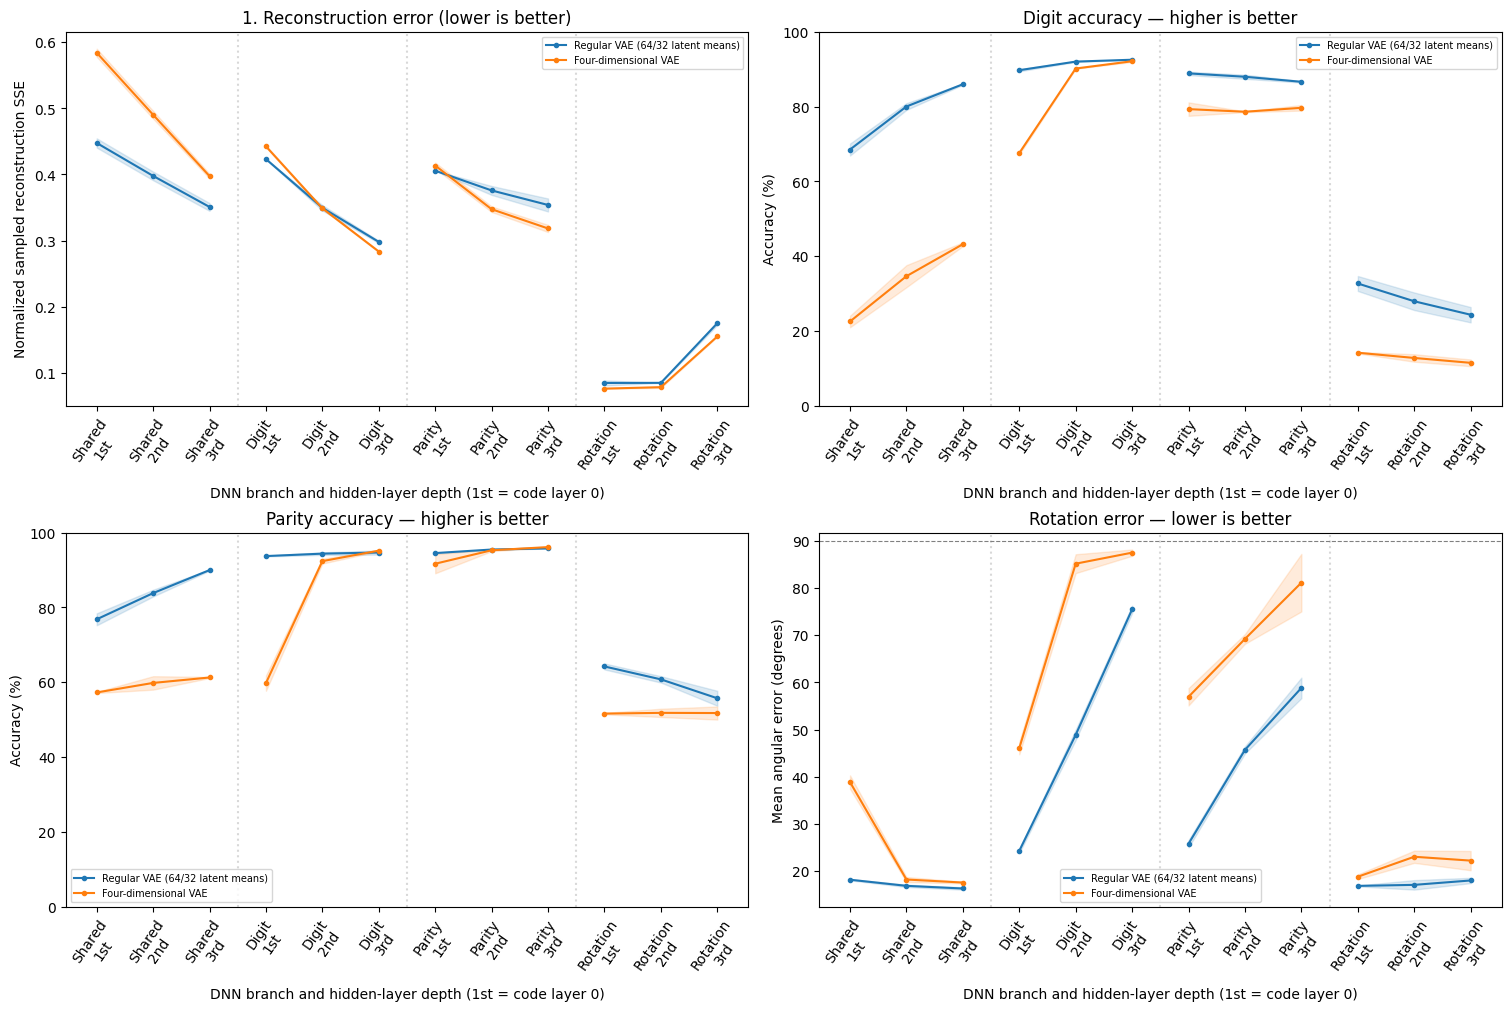

In [6]:
metrics = ['digit_bal_acc','parity_bal_acc','rotation_mae_deg','normalized_mse','sampled_normalized_mse',
    'kl','kl_per_dim','active_units','effective_rank','rank_fraction','rotation_sensitivity','input_cka','input_rsa']
summary = vae_results.groupby(['layer','variant'])[metrics].mean()
paired = vae_results.set_index(['layer','seed','variant'])[metrics]
paired_delta = paired.xs('compressed_4d',level='variant')-paired.xs('regular',level='variant')
delta = paired_delta.groupby('layer').mean().reindex(layers)

display(Markdown('### 1. Reconstruction error: how well does the decoder recover the activations?'))
display(Markdown('**Lower is better.** This table uses eight posterior samples per test observation. A value of 1 matches the training-mean prediction error; 0 is perfect reconstruction. It is separate from classification accuracy.'))
reconstruction_rows=[]
for branch in ['Shared','Digit','Parity','Rotation']:
    layer=f'{branch}_Layer_2'
    regular,compressed=[summary.loc[(layer,v),'sampled_normalized_mse'] for v in VARIANTS]
    reconstruction_rows.append({'Final hidden layer':branch,'Regular VAE error':regular,
        'Four-dimensional VAE error':compressed,'4D minus regular':compressed-regular})
reconstruction_overview=pd.DataFrame(reconstruction_rows)
display(reconstruction_overview.style.hide(axis='index').format({
    'Regular VAE error':'{:.3f}','Four-dimensional VAE error':'{:.3f}','4D minus regular':'{:+.3f}'}))
display(Markdown('### 2. Probe task performance: what can a newly trained linear model read out?'))
display(Markdown('**Higher digit/parity accuracy is better; lower rotation error is better.** Each probe is trained after its VAE is frozen and evaluated on held-out glyphs. The original activations are a contextual reference.'))

# The overview is regenerated from the fitted results, not entered by hand.
overview_rows = []
readouts = [('Shared','digit_bal_acc','Digit accuracy ↑'),('Shared','parity_bal_acc','Parity accuracy ↑'),
    ('Shared','rotation_mae_deg','Rotation error ↓'),('Digit','digit_bal_acc','Digit accuracy ↑'),
    ('Digit','rotation_mae_deg','Rotation error ↓'),('Parity','parity_bal_acc','Parity accuracy ↑'),
    ('Parity','digit_bal_acc','Digit accuracy ↑'),('Rotation','rotation_mae_deg','Rotation error ↓'),
    ('Rotation','digit_bal_acc','Digit accuracy ↑')]
for branch,metric,label in readouts:
    layer = f'{branch}_Layer_2'
    original = raw_results.loc[layer,metric]
    regular,compressed = [summary.loc[(layer,v),metric] for v in VARIANTS]
    accuracy = metric != 'rotation_mae_deg'
    values = [original,regular,compressed]
    formatted = [f'{100*x:.1f}%' if accuracy else f'{x:.1f}°' for x in values]
    change = f'{100*(compressed-regular):+.1f} pp' if accuracy else f'{compressed-regular:+.1f}°'
    overview_rows.append(dict(zip(['Final hidden layer','Readout','Original (context)','Regular VAE','Four-dimensional VAE','4D − regular'],
        [branch,label,*formatted,change])))
overview = pd.DataFrame(overview_rows)
display(overview.style.hide(axis='index').set_properties(**{'text-align':'left'}))

def expandable_table(title,table):
    display(HTML(f'<details><summary><strong>{title}</strong></summary>{table.to_html()}</details>'))
expandable_table('All 12 layers: accuracy (%) and rotation error (degrees)',
    summary[['digit_bal_acc','parity_bal_acc','rotation_mae_deg']].rename(columns={
        'digit_bal_acc':'Digit accuracy (%)','parity_bal_acc':'Parity accuracy (%)','rotation_mae_deg':'Rotation error (degrees)'}).mul(
        pd.Series({'Digit accuracy (%)':100,'Parity accuracy (%)':100,'Rotation error (degrees)':1}),axis=1).round(1))
expandable_table('Supporting diagnostics: reconstruction details, geometry, KL and latent usage',
    summary.drop(columns=['digit_bal_acc','parity_bal_acc','rotation_mae_deg']).round(3))
expandable_table('All metric changes: four-dimensional minus regular (accuracy shown as fractions)',delta.round(3))
expandable_table('Model sizes, parameter counts and selected epochs',
    vae_results.groupby(['layer','variant'])[['input_width','latent_dim','parameters','best_epoch']].mean().round(1))

labels = {'regular':'Regular VAE (64/32 latent means)','compressed_4d':'Four-dimensional VAE'}
plot_definitions = [('sampled_normalized_mse','1. Reconstruction error (lower is better)',1,'Normalized sampled reconstruction SSE'),
    ('digit_bal_acc','Digit accuracy — higher is better',100,'Accuracy (%)'),
    ('parity_bal_acc','Parity accuracy — higher is better',100,'Accuracy (%)'),
    ('rotation_mae_deg','Rotation error — lower is better',1,'Mean angular error (degrees)'),
    ('normalized_mse','Reconstruction error — lower is better',1,'Normalized mean-code SSE'),
    ('input_cka','Similarity to original activations',1,'Linear CKA'),
    ('effective_rank','Effective dimensions used',1,'Covariance effective rank')]
fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
for ax,(metric,title,scale,ylabel) in zip(axes.ravel(),plot_definitions):
    for variant in VARIANTS:
        table = vae_results.query('variant == @variant').groupby('layer')[metric].agg(['mean','min','max']).reindex(layers)*scale
        # Draw each branch separately: no connection is implied between task heads.
        for branch_index in range(4):
            positions=np.arange(branch_index*3,branch_index*3+3)
            ax.plot(positions,table['mean'].iloc[positions],'.-',color='C0' if variant=='regular' else 'C1',
                label=labels[variant] if branch_index==0 else None)
            ax.fill_between(positions,table['min'].to_numpy()[positions],table['max'].to_numpy()[positions],
                color='C0' if variant=='regular' else 'C1',alpha=.15)
    for boundary in [2.5,5.5,8.5]:
        ax.axvline(boundary,color='grey',alpha=.3,linestyle=':')
    if metric.endswith('bal_acc'):
        ax.set_ylim(0,100)
    if metric=='rotation_mae_deg':
        ax.axhline(90,color='grey',linestyle='--',linewidth=.8)
    ax.set_title(title); ax.set_ylabel(ylabel)
    ax.set_xticks(range(12),[name.split('_Layer_')[0]+'\n'+['1st','2nd','3rd'][int(name.rsplit('_',1)[1])] for name in layers],rotation=55)
    ax.set_xlabel('DNN branch and hidden-layer depth (1st = code layer 0)')
    ax.legend(fontsize=7)
fig.savefig(OUT/'figure-1.png',dpi=150,bbox_inches='tight')
plt.show()

## Granular task structure and paired uncertainty

Per-digit accuracy and within-digit angular MAE distinguish selective losses from broad changes. Each digit has 50 held-out glyphs with two views each. Exploratory per-digit extremes are not significance claims. We report both seeds separately in the saved tables and their mean in the heatmaps.

For conditional test-sample intervals, bootstrap glyphs with both views together, using fixed predictions at seed 67. Resample within each digit to preserve the balanced design. Intervals concern the four-dimensional-minus-regular change, conditional on this fitted DNN, VAEs, and probes; they exclude training-set and initialization uncertainty. Paired-seed spread is a separate optimization diagnostic.

**Digit_Layer_2: four-dimensional minus regular, by digit**

,Digit accuracy change (pp),Parity accuracy change (pp),Angular error change (degrees)
digit,,,
0,0.0,1.0,-2.3
1,-0.5,2.0,28.6
2,1.0,2.0,24.6
3,1.5,2.5,0.4
4,0.0,-0.5,15.7
5,-1.5,0.5,6.2
6,-0.5,-1.0,9.9
7,-0.5,2.5,4.1
8,-2.0,0.0,20.1


**Parity_Layer_2: four-dimensional minus regular, by digit**

,Digit accuracy change (pp),Parity accuracy change (pp),Angular error change (degrees)
digit,,,
0,-10.5,-0.5,9.8
1,1.0,0.0,11.4
2,-9.0,-2.0,29.6
3,-8.0,0.5,9.6
4,-8.0,0.0,32.4
5,-6.5,-2.0,28.6
6,-6.5,1.0,38.4
7,-12.5,0.0,21.5
8,-2.5,3.0,31.4


**Rotation_Layer_2: four-dimensional minus regular, by digit**

,Digit accuracy change (pp),Parity accuracy change (pp),Angular error change (degrees)
digit,,,
0,-11.0,-20.0,3.4
1,-23.0,-0.5,5.3
2,-2.5,-5.5,5.9
3,-13.0,7.0,3.8
4,-25.0,-3.0,3.2
5,-16.5,13.0,4.5
6,-16.5,-26.0,5.1
7,-15.0,4.5,0.9
8,-1.0,-13.0,6.7


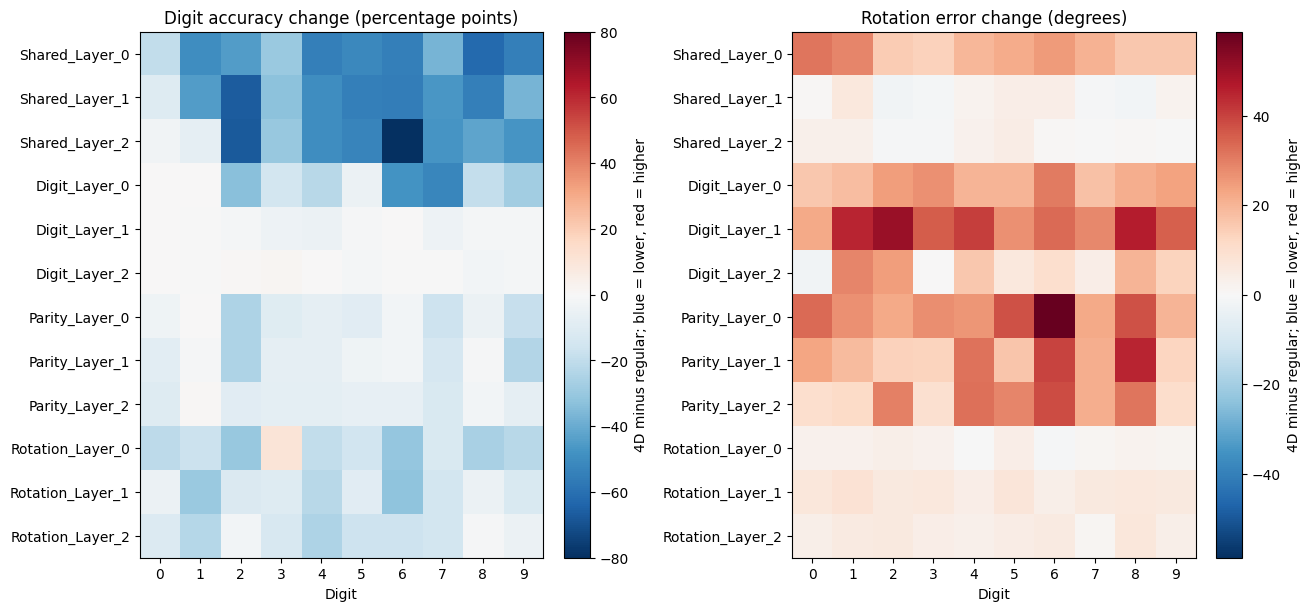

,layer,metric,delta,low,high
0,Shared_Layer_0,digit_accuracy,-0.459,-0.498,-0.418
1,Shared_Layer_0,parity_accuracy,-0.181,-0.216,-0.141
2,Shared_Layer_0,rotation_mae_deg,22.259,20.273,24.306
3,Shared_Layer_1,digit_accuracy,-0.433,-0.475,-0.397
4,Shared_Layer_1,parity_accuracy,-0.231,-0.269,-0.199
5,Shared_Layer_1,rotation_mae_deg,1.060,-0.010,2.214
6,Shared_Layer_2,digit_accuracy,-0.421,-0.455,-0.386
7,Shared_Layer_2,parity_accuracy,-0.287,-0.319,-0.255
8,Shared_Layer_2,rotation_mae_deg,1.685,0.760,2.540
9,Digit_Layer_0,digit_accuracy,-0.228,-0.257,-0.198


In [7]:
granular = granular_results.groupby(['layer','variant','digit'])[['digit_acc','parity_acc','rotation_mae_deg']].mean()
granular_delta = granular.xs('compressed_4d',level='variant')-granular.xs('regular',level='variant')
for layer in ['Digit_Layer_2','Parity_Layer_2','Rotation_Layer_2']:
    display(Markdown(f'**{layer}: four-dimensional minus regular, by digit**'))
    expandable_table(f'{layer}: per-digit changes (accuracy in percentage points)',granular_delta.loc[layer].mul(pd.Series({'digit_acc':100,'parity_acc':100,'rotation_mae_deg':1}),axis=1).rename(columns={'digit_acc':'Digit accuracy change (pp)','parity_acc':'Parity accuracy change (pp)','rotation_mae_deg':'Angular error change (degrees)'}).round(1))
fig,axes = plt.subplots(1,2,figsize=(13,6),constrained_layout=True)
for ax,metric in zip(axes,['digit_acc','rotation_mae_deg']):
    table = granular_delta[metric].unstack('digit').reindex(layers)*(100 if metric=='digit_acc' else 1)
    limit = max(abs(table.to_numpy()).max(),1e-6)
    im = ax.imshow(table,cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
    ax.set_xticks(range(10),range(10)); ax.set_xlabel('Digit')
    ax.set_yticks(range(12),layers)
    ax.set_title('Digit accuracy change (percentage points)' if metric=='digit_acc' else 'Rotation error change (degrees)')
    fig.colorbar(im,ax=ax,label='4D minus regular; blue = lower, red = higher')
fig.savefig(OUT/'figure-2.png',dpi=150,bbox_inches='tight')
plt.show()

boot_rng = np.random.default_rng(SEED)
glyph_labels = splits['test']['digit'][0::2]
draws = np.concatenate([boot_rng.choice(np.flatnonzero(glyph_labels==d),size=(500,(glyph_labels==d).sum()),replace=True)
    for d in range(10)],axis=1)
ci_rows = []
for layer in layers:
    regular,compressed = [latent_predictions[layer,v,VAE_SEEDS[0]] for v in VARIANTS]
    differences = {
        'digit_accuracy':(compressed['digit']==splits['test']['digit']).astype(float)-(regular['digit']==splits['test']['digit']).astype(float),
        'parity_accuracy':(compressed['parity']==splits['test']['digit']%2).astype(float)-(regular['parity']==splits['test']['digit']%2).astype(float),
        'rotation_mae_deg':compressed['rotation_error']-regular['rotation_error']}
    for metric,values in differences.items():
        per_glyph = values.reshape(-1,2).mean(1)
        low,high = np.quantile(per_glyph[draws].mean(1),[.025,.975])
        ci_rows.append(dict(layer=layer,metric=metric,delta=per_glyph.mean(),low=low,high=high))
bootstrap_results = pd.DataFrame(ci_rows)
expandable_table('Glyph-bootstrap intervals: fixed seed, 4D minus regular (accuracy in fractions)',bootstrap_results.round(3))

## Which layer relationships survive the dimensional bottleneck?

Repeat the first-versus-last comparison separately in each VAE's posterior-mean representations. Also compare the two VAE variants at every matching layer. Geometry metrics support unequal latent widths without requiring coordinate meanings to match. All comparisons use identical balanced test observations. Higher agreement indicates more similar geometry, not necessarily better task performance.

Training plots show sampled validation objective, including KL, at shared, digit, parity, and rotation layer 2. Selected epochs and the fraction selecting the final epoch help identify budget limits. A VAE's reconstruction and task accessibility may still improve beyond this budget.

,cka,rsa,procrustes
layer,,,
Shared_Layer_0,0.633,0.608,0.600
Shared_Layer_1,0.653,0.690,0.641
Shared_Layer_2,0.752,0.768,0.694
Digit_Layer_0,0.823,0.854,0.776
Digit_Layer_1,0.891,0.906,0.857
Digit_Layer_2,0.815,0.858,0.806
Parity_Layer_0,0.855,0.889,0.798
Parity_Layer_1,0.857,0.906,0.815
Parity_Layer_2,0.822,0.911,0.786


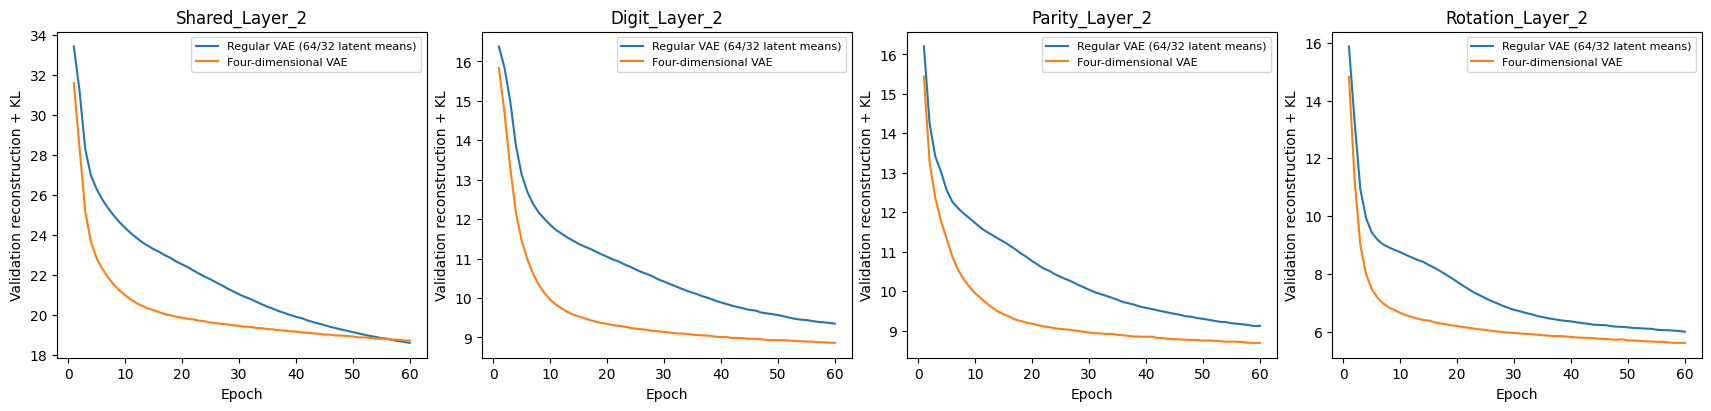

,mean_selected_epoch,fraction_final_epoch,mean_kl,mean_active_units,mean_sampled_nmse
variant,,,,,
compressed_4d,59.500,0.625,3.837,3.625,0.328
regular,59.958,0.958,4.565,20.083,0.312


In [8]:
latent_depth_rows,cross_rows = [],[]
for seed in VAE_SEEDS:
    for variant in VARIANTS:
        for branch in ['Shared','Digit','Parity','Rotation']:
            a,b = [latents[f'{branch}_Layer_{i}',variant,seed][GEOMETRY_IDX] for i in [0,2]]
            latent_depth_rows.append(dict(variant=variant,seed=seed,branch=branch,**geometry(a,b)))
    for layer in layers:
        a,b = [latents[layer,v,seed][GEOMETRY_IDX] for v in VARIANTS]
        cross_rows.append(dict(layer=layer,seed=seed,**geometry(a,b)))
latent_depth = pd.DataFrame(latent_depth_rows)
cross_geometry = pd.DataFrame(cross_rows)
expandable_table('First versus last layer: geometry by branch and VAE',latent_depth.groupby(['branch','variant'])[['cka','rsa','procrustes']].mean().round(3))
expandable_table('Regular versus four-dimensional VAE: geometry at every layer',cross_geometry.groupby('layer')[['cka','rsa','procrustes']].mean().reindex(layers).round(3))

fig,axes = plt.subplots(1,4,figsize=(17,4),constrained_layout=True)
for ax,branch in zip(axes,['Shared','Digit','Parity','Rotation']):
    layer=f'{branch}_Layer_2'
    for variant in VARIANTS:
        curve = training_curves.query('layer == @layer and variant == @variant').groupby('epoch').val_objective.mean()
        ax.plot(curve.index,curve,label=labels[variant])
    ax.set_title(layer); ax.set_xlabel('Epoch'); ax.set_ylabel('Validation reconstruction + KL'); ax.legend(fontsize=8)
fig.savefig(OUT/'figure-3.png',dpi=150,bbox_inches='tight')
plt.show()
convergence = vae_results.groupby('variant').agg(mean_selected_epoch=('best_epoch','mean'),
    fraction_final_epoch=('best_epoch',lambda x:np.mean(x==EPOCHS)),mean_kl=('kl','mean'),
    mean_active_units=('active_units','mean'),mean_sampled_nmse=('sampled_normalized_mse','mean'))
display(convergence.round(3))

## What the results mean: answering the assignment

The explanation below is generated from the same values as the overview table. “Retained” means accessible to these **linear probes**; it does not prove that all information is preserved or absent. The VAE comparison uses identical inputs and the same KL coefficient.

In [9]:
paragraphs = []
def scores(branch,metric):
    layer=f'{branch}_Layer_2'
    return tuple(summary.loc[(layer,v),metric] for v in VARIANTS)

paragraphs.append('### 1. Compared with the original unconstrained analysis')
paragraphs.append('The original activations show what the frozen DNN exposes before fitting a VAE. The regular VAE tests how much remains readable after learning a KL-regularized latent representation without reducing its nominal width. The four-dimensional VAE then adds the dimensional bottleneck. Read the original-to-regular change separately from the regular-to-four-dimensional change; neither comparison changes the DNN itself.')
a,b=scores('Shared','digit_bal_acc'); pa,pb=scores('Shared','parity_bal_acc'); ra,rb=scores('Shared','rotation_mae_deg')
paragraphs.append(f'**Shared layer: rotation survives much better than digit and parity.** At the final shared layer, digit accuracy falls '
    f'from {100*a:.1f}% to {100*b:.1f}% ({100*(b-a):+.1f} percentage points), and parity falls from '
    f'{100*pa:.1f}% to {100*pb:.1f}%. Rotation error changes only from {ra:.1f}° to {rb:.1f}°. '
    'The four-number summary therefore preserves some readable properties much better than others; it is not a uniformly faithful replacement for this shared representation.')

paragraphs.append('### 2. Differences between layers: what is easy or difficult to compress?')
a,b=scores('Digit','digit_bal_acc'); ra,rb=scores('Digit','rotation_mae_deg')
paragraphs.append(f'**Digit layer: digit identity fits into four numbers, but angle becomes harder to read.** Final digit accuracy is '
    f'{100*a:.1f}% with the regular VAE and {100*b:.1f}% with four dimensions, compared with '
    f'{100*raw_results.loc["Digit_Layer_2","digit_bal_acc"]:.1f}% in the original activations. '
    f'Rotation error rises from {ra:.1f}° to {rb:.1f}°; 90° is the unrelated-angle reference. '
    'This is selective retention of the main task of this branch, not preservation of every property of the input.')
a,b=scores('Parity','parity_bal_acc'); da,db=scores('Parity','digit_bal_acc')
paragraphs.append(f'**Parity layer: even versus odd survives better than exact digit identity.** Parity accuracy stays near '
    f'{100*b:.1f}% ({100*a:.1f}% regular), while digit accuracy falls from {100*da:.1f}% to {100*db:.1f}%. '
    'The compressed code can retain the distinction needed for parity while making distinctions between individual digits less accessible. '
    'Because parity is determined by digit, these readouts overlap rather than measure independent factors.')
a,b=scores('Rotation','rotation_mae_deg'); da,db=scores('Rotation','digit_bal_acc')
paragraphs.append(f'**Rotation layer: angle remains much more accessible than digit identity.** Angular error increases '
    f'from {a:.1f}° to {b:.1f}° ({b-a:+.1f}°), while digit accuracy falls from {100*da:.1f}% to '
    f'{100*db:.1f}%, close to the 10% digit-chance reference. '
    'The task branches therefore respond differently to the same four-dimensional limit.')
paragraphs.append('**Depth and individual digits add detail.** The full layer plots show where the differences develop; the per-digit heatmap '
    'shows whether the average hides selective losses. At the final digit layer, the largest digit-accuracy decrease is for digit '
    f'{int(granular_delta.loc["Digit_Layer_2"].digit_acc.idxmin())} '
    f'({100*granular_delta.loc["Digit_Layer_2"].digit_acc.min():+.1f} points). '
    'These per-digit extremes are exploratory, not independent significance tests.')

paragraphs.append('### 3. What the four-dimensional constraint changes — and what CKA adds')
layer='Rotation_Layer_2'
a,b=[summary.loc[(layer,v),'input_cka'] for v in VARIANTS]
paragraphs.append(f'**Overall geometry can look similar while a particular readout worsens.** At the final rotation layer, '
    f'CKA between original activations and the VAE latent means is {a:.3f} for the regular VAE and {b:.3f} for the '
    'four-dimensional VAE. Both matrices contain the same images in the same row order. CKA asks whether their overall '
    'patterns of variation across images agree; the digit probe asks whether digit identity is linearly readable. '
    'High CKA alongside a digit-accuracy drop shows why geometry alone is not a complete measure of task information.')
paragraphs.append('**This is a dimensionality comparison, with KL in both models.** A reconstruction objective does not assign equal '
    'importance to preserving digit, parity, and angle labels. Four dimensions can preserve the dominant structure of a specialized '
    'layer while weakening secondary readouts. Similar reconstruction error also does not guarantee similar task accuracy. '
    'KL totals and effective rank are supporting diagnostics, not evidence that individual coordinates correspond to independent semantic factors.')
c=convergence.loc['regular']; d=convergence.loc['compressed_4d']
paragraphs.append(f'**How strong is this conclusion?** These results apply to the tested VAEs, two training seeds, and linear probes. '
    f'{100*c.fraction_final_epoch:.1f}% of regular fits and {100*d.fraction_final_epoch:.1f}% of four-dimensional fits selected '
    f'the final epoch of the {EPOCHS}-epoch budget, so the exact differences may also depend on further optimization. '
    'The glyph-bootstrap intervals assess held-out-sample variation for one fixed seed; they do not establish uncertainty over all possible training runs.')
interpretation='\n\n'.join(paragraphs)
display(Markdown(interpretation))

### 1. Compared with the original unconstrained analysis

The original activations show what the frozen DNN exposes before fitting a VAE. The regular VAE tests how much remains readable after learning a KL-regularized latent representation without reducing its nominal width. The four-dimensional VAE then adds the dimensional bottleneck. Read the original-to-regular change separately from the regular-to-four-dimensional change; neither comparison changes the DNN itself.

**Shared layer: rotation survives much better than digit and parity.** At the final shared layer, digit accuracy falls from 85.9% to 43.2% (-42.7 percentage points), and parity falls from 90.0% to 61.3%. Rotation error changes only from 16.3° to 17.6°. The four-number summary therefore preserves some readable properties much better than others; it is not a uniformly faithful replacement for this shared representation.

### 2. Differences between layers: what is easy or difficult to compress?

**Digit layer: digit identity fits into four numbers, but angle becomes harder to read.** Final digit accuracy is 92.5% with the regular VAE and 92.1% with four dimensions, compared with 92.4% in the original activations. Rotation error rises from 75.5° to 87.5°; 90° is the unrelated-angle reference. This is selective retention of the main task of this branch, not preservation of every property of the input.

**Parity layer: even versus odd survives better than exact digit identity.** Parity accuracy stays near 96.1% (95.8% regular), while digit accuracy falls from 86.6% to 79.7%. The compressed code can retain the distinction needed for parity while making distinctions between individual digits less accessible. Because parity is determined by digit, these readouts overlap rather than measure independent factors.

**Rotation layer: angle remains much more accessible than digit identity.** Angular error increases from 18.0° to 22.2° (+4.2°), while digit accuracy falls from 24.3% to 11.5%, close to the 10% digit-chance reference. The task branches therefore respond differently to the same four-dimensional limit.

**Depth and individual digits add detail.** The full layer plots show where the differences develop; the per-digit heatmap shows whether the average hides selective losses. At the final digit layer, the largest digit-accuracy decrease is for digit 8 (-2.0 points). These per-digit extremes are exploratory, not independent significance tests.

### 3. What the four-dimensional constraint changes — and what CKA adds

**Overall geometry can look similar while a particular readout worsens.** At the final rotation layer, CKA between original activations and the VAE latent means is 0.928 for the regular VAE and 0.919 for the four-dimensional VAE. Both matrices contain the same images in the same row order. CKA asks whether their overall patterns of variation across images agree; the digit probe asks whether digit identity is linearly readable. High CKA alongside a digit-accuracy drop shows why geometry alone is not a complete measure of task information.

**This is a dimensionality comparison, with KL in both models.** A reconstruction objective does not assign equal importance to preserving digit, parity, and angle labels. Four dimensions can preserve the dominant structure of a specialized layer while weakening secondary readouts. Similar reconstruction error also does not guarantee similar task accuracy. KL totals and effective rank are supporting diagnostics, not evidence that individual coordinates correspond to independent semantic factors.

**How strong is this conclusion?** These results apply to the tested VAEs, two training seeds, and linear probes. 95.8% of regular fits and 62.5% of four-dimensional fits selected the final epoch of the 60-epoch budget, so the exact differences may also depend on further optimization. The glyph-bootstrap intervals assess held-out-sample variation for one fixed seed; they do not establish uncertainty over all possible training runs.

## Limits and reproducibility

- “Regular VAE” here means latent width matching the input layer (64 or 32). It retains KL and finite-model constraints; it is not a universally unconstrained model. The four-dimensional VAE changes only latent width and the resulting parameter count/KL dimensionality. Both hidden widths stay 128, both KL coefficients stay 1, and the DNN checkpoint stays fixed.
- Two seeds and 2,000 training glyphs provide a bounded experiment, not population-level evidence. Inspect validation objectives and selected epochs. A final-epoch selection suggests trying a larger budget before claiming convergence. Seeds share data order, but different architectures cannot have identical initialization/noise tensors.
- The analysis measures posterior-mean geometry and linear readouts. Information can remain present in nonlinear forms. Rotation probes access first-harmonic sine/cosine codes; errors near 90 degrees indicate little benefit under this readout, not a proof of absent rotation information.
- KL is computed against the standard-normal prior and is not reported as a direct mutual-information estimate. Low KL, high rank fraction, or active coordinates do not prove disentanglement. Total KL comparisons must account for the different number of coordinates.
- A same-glyph rotation-sensitivity ratio is relative to within-digit glyph variation and includes interpolation effects. It is not a derivative or proof of perfect invariance. Digit and parity are overlapping targets.
- Bootstrap intervals resample held-out glyphs within digit and keep both rotated views together. They condition on the fitted models/probes at seed 67. They exclude checkpoint and training-sample uncertainty. No independent-sample significance test is applied to pairwise distances.
- Fitting activation VAEs changes how the DNN layers are represented for analysis; it does not change the frozen DNN or its predictions. This experiment uses one unconstrained wide checkpoint and does not compare different network orthogonality penalties or any zero-KL model.
- A standard-normal prior is rotationally symmetric; individual latent axes have no guaranteed task meaning. CKA/RSA/Procrustes compare geometry without assigning digit/rotation labels to coordinates.
- Reruns can reuse saved fits only when the experiment configuration, versions, DNN hash, stimulus metadata and required files match. Change `EXPERIMENT_VERSION` or disable `REUSE_FITTED_VAES` after editing training code. The first execution trains all 48 VAEs; the two settings both keep KL. Previous experiment artifacts are not used.

In [10]:
tables = {'reconstruction_overview':reconstruction_overview,'final_layer_overview':overview,'original_layer_reference':raw_results.reset_index(),'original_depth_reference':depth_geometry.reset_index(),
    'vae_metrics':vae_results,'training_curves':training_curves,'per_digit_metrics':granular_results,
    'dimension_deltas':delta.reset_index(),'paired_seed_deltas':paired_delta.reset_index(),
    'bootstrap_intervals':bootstrap_results,'latent_depth_geometry':latent_depth,
    'cross_variant_geometry':cross_geometry,'network_reference':network_results,'convergence':convergence.reset_index()}
for name,table in tables.items():
    table.to_csv(OUT/f'{name}.csv',index=False)
np.savez_compressed(OUT/'stimulus_metadata.npz',**{f'{s}_{k}':v for s,data in splits.items() for k,v in data.items() if k!='images'})
np.savez_compressed(OUT/'test_latents.npz',**{'__'.join(map(str,k)):v for k,v in latents.items()})
np.savez_compressed(OUT/'test_probe_predictions.npz',**{'__'.join(map(str,k))+'__'+task:pred
    for k,predictions in latent_predictions.items() for task,pred in predictions.items()})
(OUT/'manifest.json').write_text(json.dumps(dict(config=config,versions=versions),indent=2))
(OUT/'interpretation.txt').write_text(interpretation,encoding='utf-8')
assert len(vae_results)==len(layers)*len(VAE_SEEDS)*len(VARIANTS)==48
assert set(vae_results.variant)==set(VARIANTS) and vae_results.beta.eq(1).all()
assert (vae_results.query('variant == "regular"').latent_dim==vae_results.query('variant == "regular"').input_width).all()
assert vae_results.query('variant == "compressed_4d"').latent_dim.eq(4).all()
assert np.isfinite(vae_results[metrics]).all().all(), 'Inspect any undefined metrics before interpretation'
print('Saved 48 KL-regularized VAE fits and',len(tables),'tables to',OUT)

Saved 48 KL-regularized VAE fits and 14 tables to C:\Users\taeju\DSC180A\rotated-MNIST\vae-dimension-results
